<a href="https://colab.research.google.com/github/moreen819/project/blob/main/Project_unified_data_trial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

In [ ]:
df = pd.read_csv('ran_unified_pm_cm_fm_hourly.csv')
df.head()

,timestamp,cell_id,site_id,sector,area_type,technology,operational_state,scenario_label,active_users,traffic_dl_gb,...,ho_in_attempts_21d,time_hour,time_day_of_week,time_is_weekend,time_date,unified_radio_signal_dbm,unified_radio_signal_metric,unified_radio_quality,unified_radio_quality_metric,data_is_synthetic
0,2026-10-01 00:00:00,S01-SEC1-2G,S01,1,Urban,2G,ACTIVE,normal,6,0.043,...,11298,0,3,0,2026-10-01,-81.9,RXLEV,1.0,RXQUAL,1
1,2026-10-01 00:00:00,S01-SEC1-3G,S01,1,Urban,3G,ACTIVE,normal,9,0.739,...,10647,0,3,0,2026-10-01,-81.2,RSCP,-9.8,ECNO,1
2,2026-10-01 00:00:00,S01-SEC1-4G,S01,1,Urban,4G,ACTIVE,normal,50,49.680,...,12810,0,3,0,2026-10-01,-83.9,RSRP,-10.6,RSRQ,1
3,2026-10-01 00:00:00,S01-SEC1-5G,S01,1,Urban,5G,ACTIVE,normal,47,155.520,...,14469,0,3,0,2026-10-01,-85.0,SS_RSRP,-11.2,SS_RSRQ,1
4,2026-10-01 00:00:00,S01-SEC2-2G,S01,2,Urban,2G,ACTIVE,normal,6,0.041,...,10479,0,3,0,2026-10-01,-78.7,RXLEV,2.0,RXQUAL,1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df.duplicated(subset=['timestamp', 'cell_id']).sum()

np.int64(0)

In [ ]:
df.groupby('timestamp').size()               # number of rows for each hour

,0
timestamp,
2026-10-01 00:00:00,120
2026-10-01 01:00:00,120
2026-10-01 02:00:00,120
2026-10-01 03:00:00,120
2026-10-01 04:00:00,120
...,...
2026-10-21 19:00:00,120
2026-10-21 20:00:00,120
2026-10-21 21:00:00,120


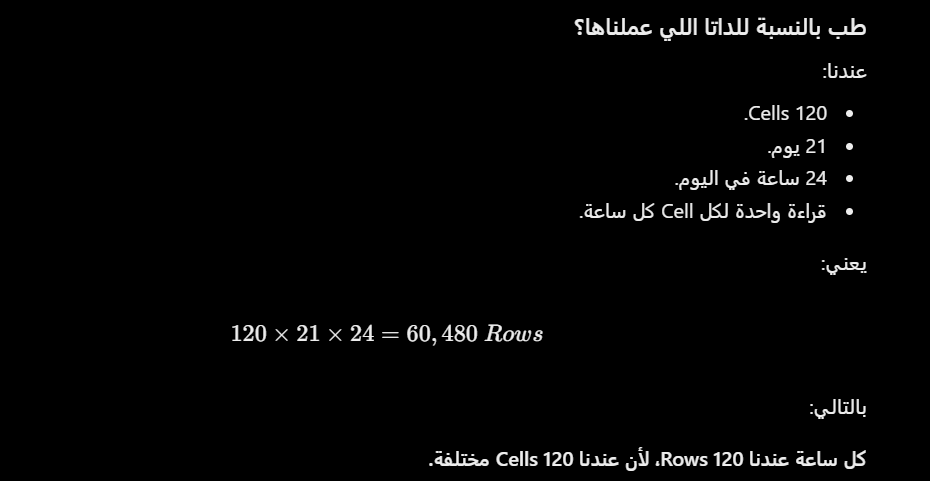

In [ ]:
df.shape

(60480, 81)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60480 entries, 0 to 60479
Data columns (total 81 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   timestamp                     60480 non-null  object 
 1   cell_id                       60480 non-null  object 
 2   site_id                       60480 non-null  object 
 3   sector                        60480 non-null  int64  
 4   area_type                     60480 non-null  object 
 5   technology                    60480 non-null  object 
 6   operational_state             60480 non-null  object 
 7   scenario_label                60480 non-null  object 
 8   active_users                  60480 non-null  int64  
 9   traffic_dl_gb                 60480 non-null  float64
 10  traffic_ul_gb                 60480 non-null  float64
 11  load_pct                      60480 non-null  float64
 12  prb_dl_util_pct               30240 non-null  float64
 13  t

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(df['timestamp'].dtype)
print(df['timestamp'].min())
print(df['timestamp'].max())

datetime64[ns]
2026-10-01 00:00:00
2026-10-21 23:00:00


In [ ]:
# Check completely duplicated rows
print("Full duplicated rows:", df.duplicated().sum())

# Check duplicated cell readings at the same timestamp
print(
    "Duplicated Cell-Timestamp:",
    df.duplicated(subset=['cell_id', 'timestamp']).sum()
)

Full duplicated rows: 0
Duplicated Cell-Timestamp: 0


In [ ]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0]

missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

,Missing_Count,Missing_Percentage
fm_active_alarm_types,59958,99.136905
fm_active_alarm_ids,59958,99.136905
tch_util_pct,45360,75.000000
ecno_db,45360,75.000000
rxlev_dbm,45360,75.000000
rscp_dbm,45360,75.000000
rxqual_0_7,45360,75.000000
hspa_code_util_pct,45360,75.000000
cssr_pct,31125,51.463294
session_setup_success_pct,30941,51.159061


In [ ]:
kpi_checks = [
    ('ho_success_rate_pct', 'ho_attempts'),
    ('paging_success_rate_pct', 'paging_attempts'),
    ('location_update_success_pct', 'location_update_attempts')
]

for kpi, attempts in kpi_checks:

    missing = df[kpi].isna()
    zero_attempts = df[attempts] == 0

    print(f"\n{kpi}")
    print("Missing values:", missing.sum())
    print("Zero attempts:", zero_attempts.sum())

    print(
        "Missing with positive attempts:",
        (missing & ~zero_attempts).sum()
    )

    print(
        "Defined with zero attempts:",
        (~missing & zero_attempts).sum()
    )


ho_success_rate_pct
Missing values: 9785
Zero attempts: 9785
Missing with positive attempts: 0
Defined with zero attempts: 0

paging_success_rate_pct
Missing values: 3595
Zero attempts: 3595
Missing with positive attempts: 0
Defined with zero attempts: 0

location_update_success_pct
Missing values: 14132
Zero attempts: 14132
Missing with positive attempts: 0
Defined with zero attempts: 0


In [ ]:
columns_to_check = [
    'avg_dl_user_throughput_mbps',
    'drop_rate_pct',
    'latency_ms',
    'packet_loss_pct',
    'jitter_ms'
]

print("Operational States:")
print(df['operational_state'].value_counts())

print("\nMissing Values by Operational State:")

print(
    df.groupby('operational_state')[columns_to_check]
      .apply(lambda x: x.isna().sum())
)

Operational States:
operational_state
ACTIVE    59793
SLEEP       687
Name: count, dtype: int64

Missing Values by Operational State:
                   avg_dl_user_throughput_mbps  drop_rate_pct  latency_ms  \
operational_state                                                           
ACTIVE                                       0              0           0   
SLEEP                                      687            687         687   

                   packet_loss_pct  jitter_ms  
operational_state                              
ACTIVE                           0          0  
SLEEP                          687        687  


In [ ]:
# Check invalid ranges
checks = {
    'Negative Active Users': (df['active_users'] < 0).sum(),

    'Invalid Load Percentage':
        ((df['load_pct'] < 0) | (df['load_pct'] > 100)).sum(),

    'Negative DL Traffic':
        (df['traffic_dl_gb'] < 0).sum(),

    'Negative UL Traffic':
        (df['traffic_ul_gb'] < 0).sum(),

    'Invalid PRB Utilization':
        ((df['prb_dl_util_pct'] < 0) |
         (df['prb_dl_util_pct'] > 100)).sum(),

    'Invalid Handover Counters':
        (df['ho_successes'] > df['ho_attempts']).sum(),

    'Invalid Paging Counters':
        (df['paging_successes'] > df['paging_attempts']).sum(),

    'Negative Energy Consumption':
        (df['energy_consumption_kwh'] < 0).sum()
}

pd.DataFrame(
    checks.items(),
    columns=['Validation Check', 'Invalid Rows']
)

,Validation Check,Invalid Rows
0,Negative Active Users,0
1,Invalid Load Percentage,0
2,Negative DL Traffic,0
3,Negative UL Traffic,0
4,Invalid PRB Utilization,0
5,Invalid Handover Counters,0
6,Invalid Paging Counters,0
7,Negative Energy Consumption,0


In [ ]:
kpi_checks = [
    ('ho_success_rate_pct', 'ho_successes', 'ho_attempts'),
    ('paging_success_rate_pct', 'paging_successes', 'paging_attempts'),
    ('location_update_success_pct',
     'location_update_successes',
     'location_update_attempts')
]

for kpi, successes, attempts in kpi_checks:

    calculated = np.where(
        df[attempts] > 0,
        df[successes] / df[attempts].replace(0, np.nan) * 100,
        np.nan
    )

    difference = np.abs(df[kpi] - calculated)

    invalid = (difference > 0.01).sum()

    print(f"{kpi}: {invalid} inconsistent rows")

ho_success_rate_pct: 0 inconsistent rows
paging_success_rate_pct: 0 inconsistent rows
location_update_success_pct: 0 inconsistent rows


In [ ]:
features = [
    'load_pct',
    'active_users',
    'avg_dl_user_throughput_mbps',
    'energy_consumption_kwh'
]

df[features].describe()

,load_pct,active_users,avg_dl_user_throughput_mbps,energy_consumption_kwh
count,60480.000000,60480.000000,59793.000000,60480.000000
mean,30.754336,41.996396,10.276309,0.392390
std,19.539540,42.622569,13.993267,0.192893
min,0.000000,0.000000,0.031000,0.119600
25%,16.170000,10.000000,0.097000,0.222700
50%,27.030000,21.000000,1.604000,0.290100
75%,41.832500,71.000000,13.024000,0.560700
max,99.500000,249.000000,81.259000,0.945200


In [ ]:
features = [
    'load_pct',
    'active_users',
    'avg_dl_user_throughput_mbps',
    'energy_consumption_kwh'
]

df.groupby('technology')[features].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

load_pct                    active_users                  \
               mean median  min    max         mean median min  max   
technology                                                            
2G            25.80  24.78  1.5  84.57        10.36   10.0   1   38   
3G            21.27  20.25  1.5  72.00        12.92   12.0   1   51   
4G            41.24  40.70  1.5  99.50        72.30   71.0   1  210   
5G            34.69  34.39  0.0  99.50        72.41   71.0   0  249   

           avg_dl_user_throughput_mbps                      \
                                  mean median   min    max   
technology                                                   
2G                                0.07   0.07  0.03   0.12   
3G                                1.15   1.15  0.42   2.08   
4G                                8.17   8.05  0.67  19.88   
5G                               32.73  32.28  4.07  81.26   

           energy_consumption_kwh                     
                             mean median   min   max  
technology                                            
2G                           0.20   0.20  0.16  0.28  
3G                           0.25   0.25  0.19  0.35  
4G                           0.48   0.48  0.32  0.67  
5G                           0.64   0.65  0.12  0.95

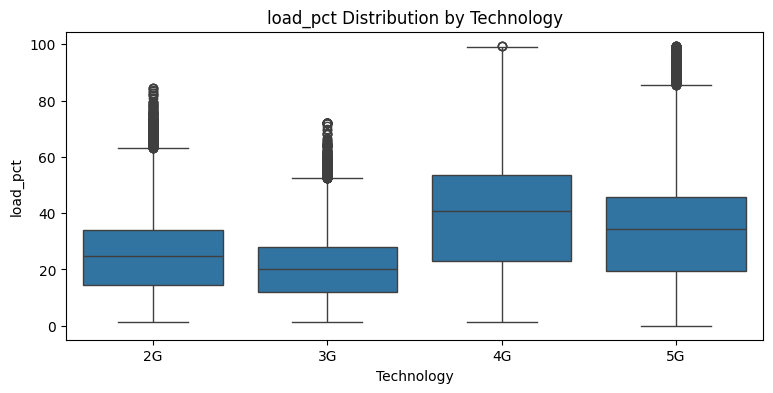

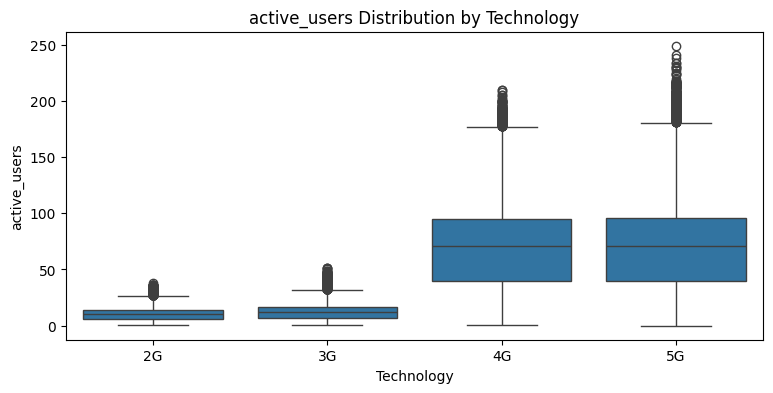

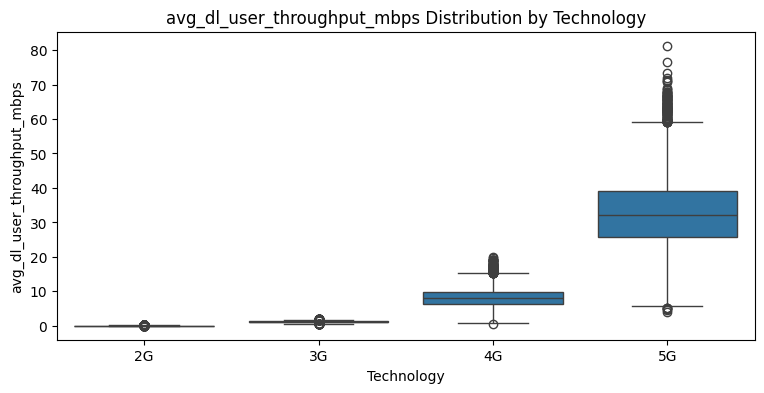

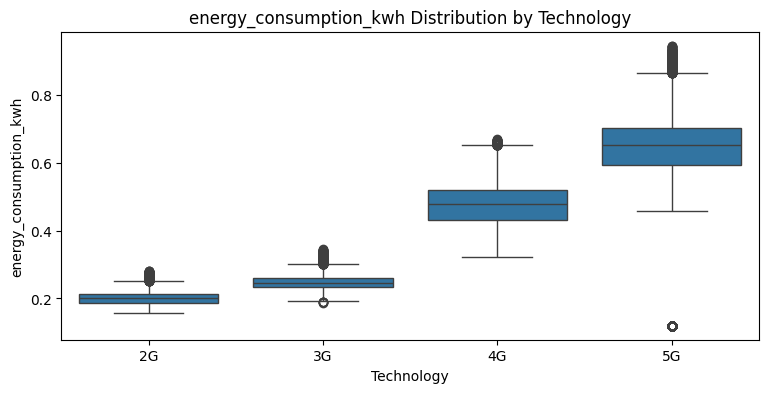

In [ ]:
features = [
    'load_pct',
    'active_users',
    'avg_dl_user_throughput_mbps',
    'energy_consumption_kwh'
]

for feature in features:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=df,
        x='technology',
        y=feature
    )

    plt.title(f'{feature} Distribution by Technology')
    plt.xlabel('Technology')
    plt.ylabel(feature)
    plt.show()

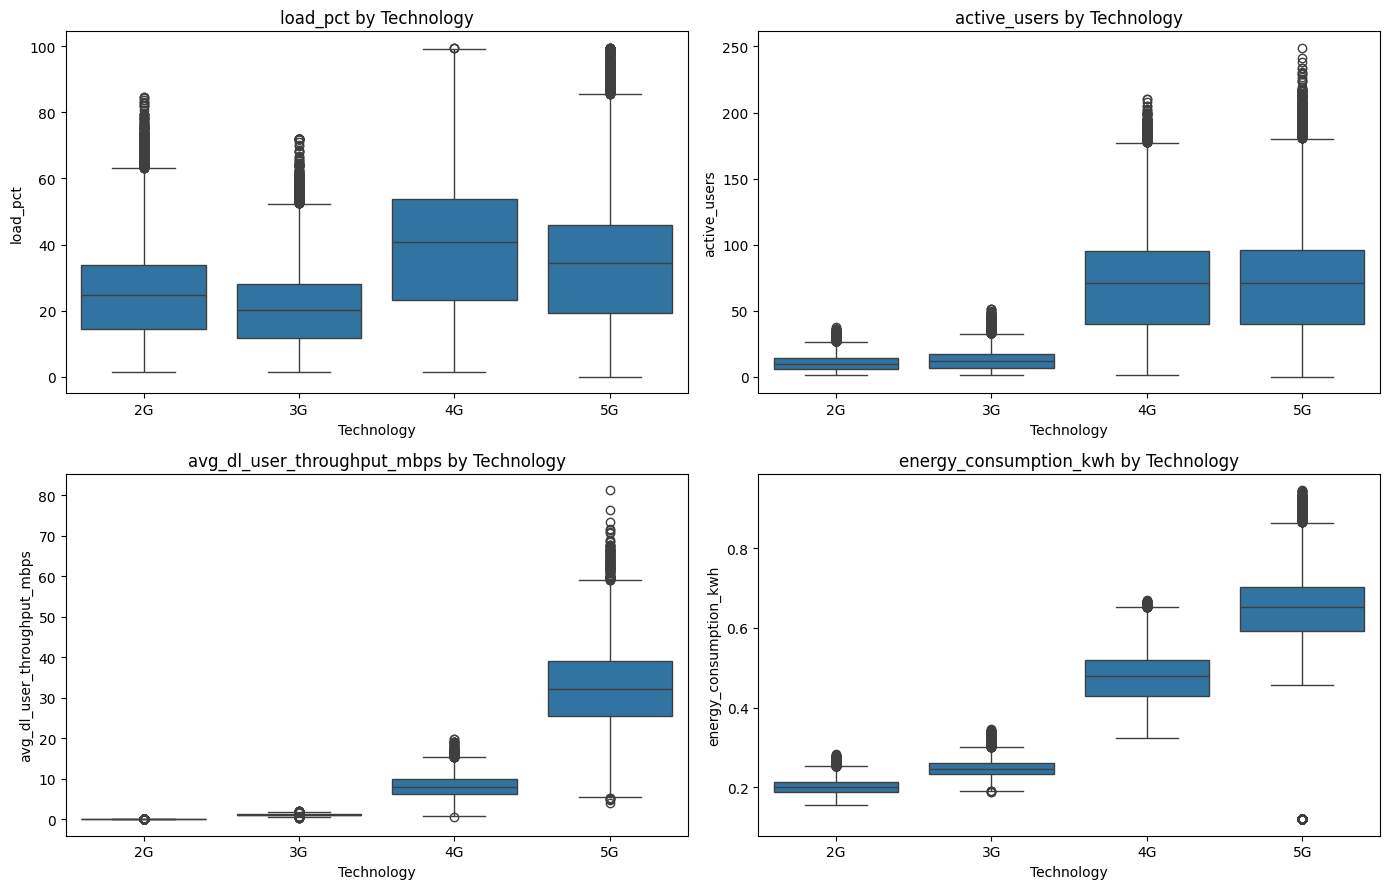

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

features = [
    'load_pct',
    'active_users',
    'avg_dl_user_throughput_mbps',
    'energy_consumption_kwh'
]

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        data=df,
        x='technology',
        y=feature,
        ax=ax
    )

    ax.set_title(f'{feature} by Technology')
    ax.set_xlabel('Technology')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

In [ ]:
df[df['technology'] == '5G'].groupby(
    'operational_state'
)['energy_consumption_kwh'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
operational_state,,,,,,,,
ACTIVE,14433.0,0.662,0.079,0.457,0.60,0.658,0.705,0.945
SLEEP,687.0,0.120,0.000,0.120,0.12,0.120,0.120,0.120


In [ ]:
df[
    (df['technology'] == '5G') &
    (df['energy_consumption_kwh'] < 0.2)
][[
    'timestamp',
    'cell_id',
    'operational_state',
    'load_pct',
    'active_users',
    'energy_consumption_kwh'
]].head(15)

,timestamp,cell_id,operational_state,load_pct,active_users,energy_consumption_kwh
139,2026-10-01 01:00:00,S02-SEC2-5G,SLEEP,0.0,0,0.1196
151,2026-10-01 01:00:00,S03-SEC2-5G,SLEEP,0.0,0,0.1196
167,2026-10-01 01:00:00,S04-SEC3-5G,SLEEP,0.0,0,0.1196
223,2026-10-01 01:00:00,S09-SEC2-5G,SLEEP,0.0,0,0.1196
235,2026-10-01 01:00:00,S10-SEC2-5G,SLEEP,0.0,0,0.1196
247,2026-10-01 02:00:00,S01-SEC2-5G,SLEEP,0.0,0,0.1196
259,2026-10-01 02:00:00,S02-SEC2-5G,SLEEP,0.0,0,0.1196
279,2026-10-01 02:00:00,S04-SEC1-5G,SLEEP,0.0,0,0.1196
287,2026-10-01 02:00:00,S04-SEC3-5G,SLEEP,0.0,0,0.1196
299,2026-10-01 02:00:00,S05-SEC3-5G,SLEEP,0.0,0,0.1196


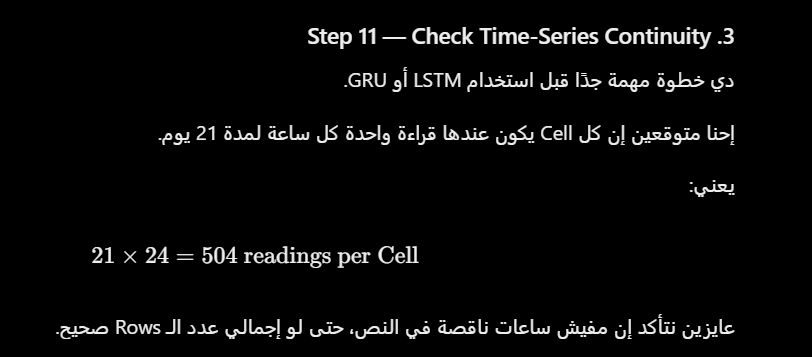

In [ ]:
# Sort data by cell and timestamp
df = df.sort_values(['cell_id', 'timestamp']).reset_index(drop=True)

# Calculate time difference between consecutive readings
df['time_diff'] = df.groupby('cell_id')['timestamp'].diff()

# Find unexpected time gaps
time_gaps = df[
    df['time_diff'].notna() &
    (df['time_diff'] != pd.Timedelta(hours=1))
]

print("Cells:", df['cell_id'].nunique())

print("Expected readings per cell:", 21 * 24)

print("Unexpected time gaps:", len(time_gaps))

# Check number of readings per cell
print("\nReadings per cell:")
print(df.groupby('cell_id').size().describe())

Cells: 120
Expected readings per cell: 504
Unexpected time gaps: 0

Readings per cell:
count    120.0
mean     504.0
std        0.0
min      504.0
25%      504.0
50%      504.0
75%      504.0
max      504.0
dtype: float64


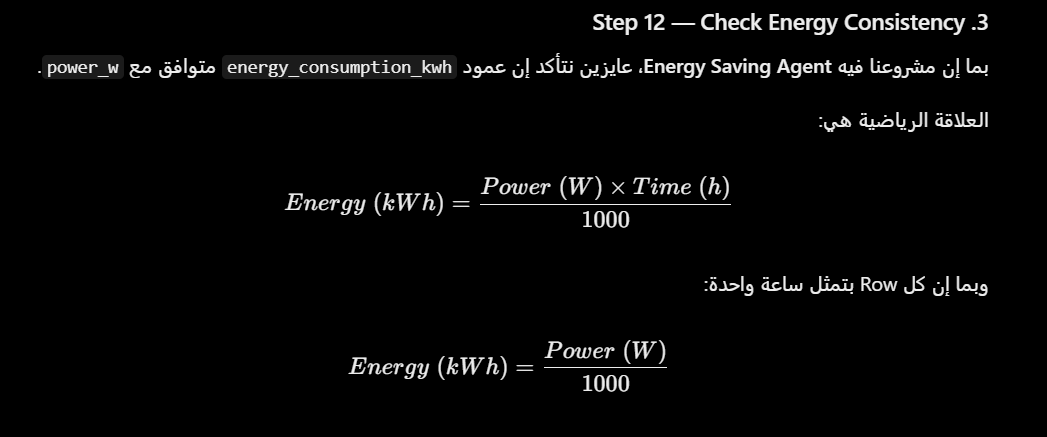

In [ ]:
# Calculate expected energy for a 1-hour interval
expected_energy = df['power_w'] / 1000

# Compare with stored energy consumption
energy_difference = abs(
    df['energy_consumption_kwh'] - expected_energy
)

print("Inconsistent energy rows:",
      (energy_difference > 0.001).sum())

print("Maximum energy difference:",
      energy_difference.max())

Inconsistent energy rows: 0
Maximum energy difference: 1.1102230246251565e-16


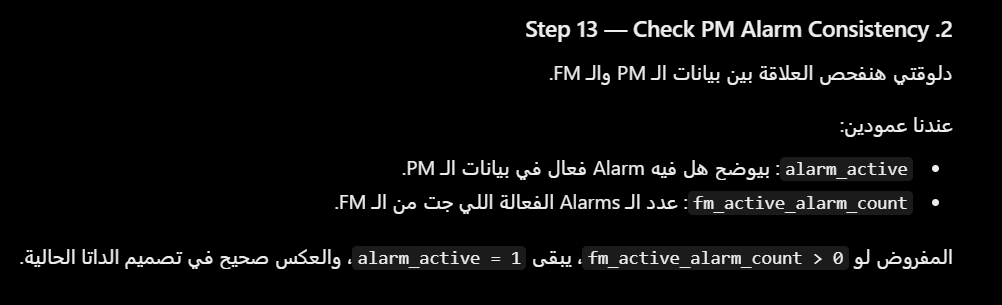

In [ ]:
# Convert FM alarm count into a binary flag
fm_alarm_flag = (df['fm_active_alarm_count'] > 0).astype(int)

# Compare PM alarm flag with FM alarm status
alarm_mismatch = df['alarm_active'] != fm_alarm_flag

print("Inconsistent Alarm Rows:", alarm_mismatch.sum())

# Check alarm distribution
print("\nAlarm Distribution:")
print(df['alarm_active'].value_counts())

# Check FM severity distribution
print("\nFM Severity Distribution:")
print(df['fm_max_severity'].value_counts())

Inconsistent Alarm Rows: 0

Alarm Distribution:
alarm_active
0    59958
1      522
Name: count, dtype: int64

FM Severity Distribution:
fm_max_severity
NONE        59958
MAJOR         355
CRITICAL      167
Name: count, dtype: int64


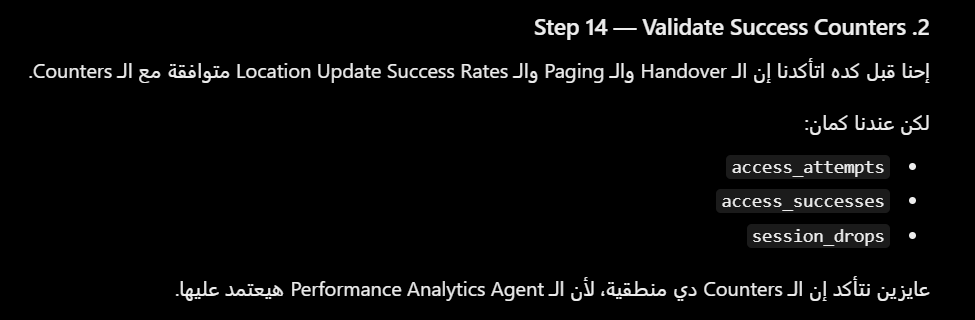

In [ ]:
# Check access counter consistency
invalid_access = (
    df['access_successes'] > df['access_attempts']
).sum()

negative_attempts = (
    df['access_attempts'] < 0
).sum()

negative_successes = (
    df['access_successes'] < 0
).sum()

negative_drops = (
    df['session_drops'] < 0
).sum()

print("Invalid Access Counters:", invalid_access)
print("Negative Access Attempts:", negative_attempts)
print("Negative Access Successes:", negative_successes)
print("Negative Session Drops:", negative_drops)

Invalid Access Counters: 0
Negative Access Attempts: 0
Negative Access Successes: 0
Negative Session Drops: 0


# **Step 15 — Separate Features and Labels**

In [ ]:
# Keep ground-truth labels separately
labels = df[
    ['timestamp', 'cell_id', 'is_anomaly', 'scenario_label']
].copy()

# Remove ground-truth labels from candidate input data
X = df.drop(
    columns=['is_anomaly', 'scenario_label']
).copy()

print("Original Dataset:", df.shape)
print("Candidate Inputs:", X.shape)
print("Labels:", labels.shape)

display(labels.head())

Original Dataset: (60480, 82)
Candidate Inputs: (60480, 80)
Labels: (60480, 4)


,timestamp,cell_id,is_anomaly,scenario_label
0,2026-10-01 00:00:00,S01-SEC1-2G,0,normal
1,2026-10-01 01:00:00,S01-SEC1-2G,0,normal
2,2026-10-01 02:00:00,S01-SEC1-2G,0,normal
3,2026-10-01 03:00:00,S01-SEC1-2G,0,normal
4,2026-10-01 04:00:00,S01-SEC1-2G,0,normal


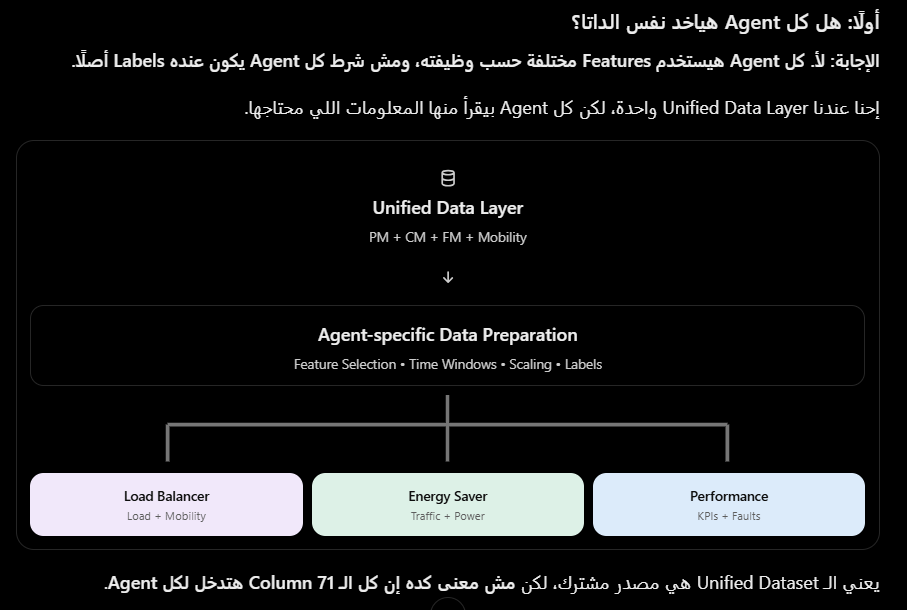

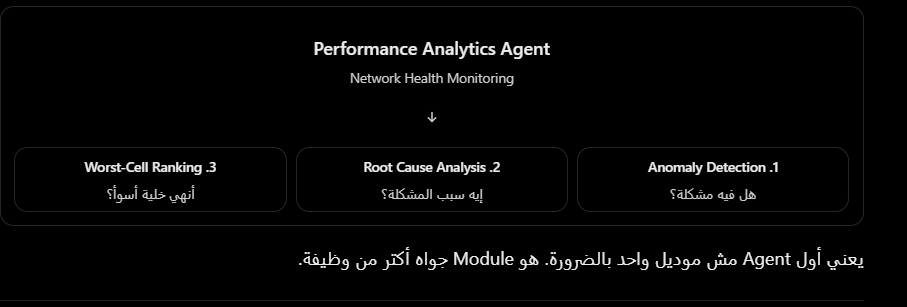

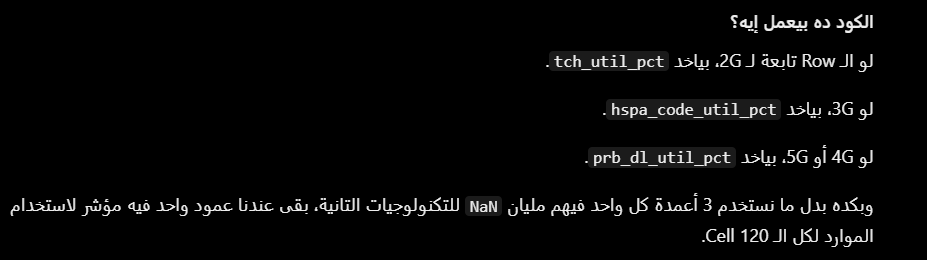

In [ ]:
X['resource_util_pct'] = np.select(
    [
        X['technology'] == '2G',
        X['technology'] == '3G',
        X['technology'].isin(['4G', '5G'])
    ],
    [
        X['tch_util_pct'],
        X['hspa_code_util_pct'],
        X['prb_dl_util_pct']
    ],
    default=np.nan
)

print(
    X.groupby('technology')['resource_util_pct']
     .agg(['count', 'mean', 'min', 'max'])
     .round(2)
)

            count   mean  min    max
technology                          
2G          15120  25.80  1.5  84.57
3G          15120  21.27  1.5  72.00
4G          15120  41.24  1.5  99.50
5G          15120  34.69  0.0  99.50


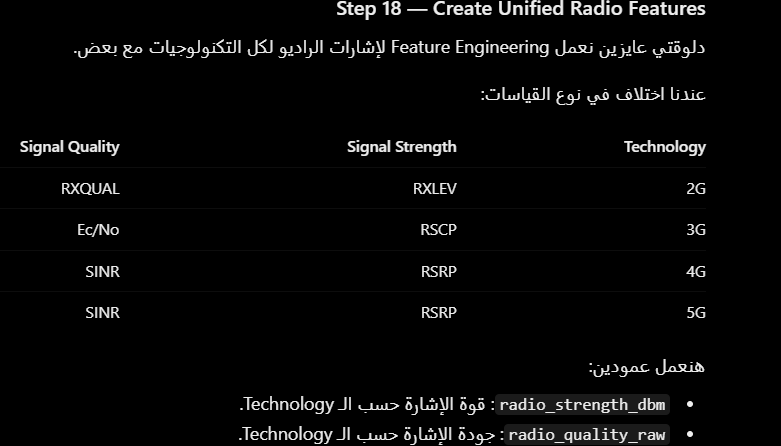

In [ ]:
X['radio_strength_dbm'] = np.select(
    [
        X['technology'] == '2G',
        X['technology'] == '3G',
        X['technology'].isin(['4G', '5G'])
    ],
    [
        X['rxlev_dbm'],
        X['rscp_dbm'],
        X['rsrp_dbm']
    ],
    default=np.nan
)

X['radio_quality_raw'] = np.select(
    [
        X['technology'] == '2G',
        X['technology'] == '3G',
        X['technology'].isin(['4G', '5G'])
    ],
    [
        X['rxqual_0_7'],
        X['ecno_db'],
        X['sinr_db']
    ],
    default=np.nan
)

# Check the new features
print(
    X.groupby('technology')[
        ['radio_strength_dbm', 'radio_quality_raw']
    ].agg(['count', 'mean', 'min', 'max']).round(2)
)

           radio_strength_dbm                     radio_quality_raw         \
                        count   mean    min   max             count   mean   
technology                                                                   
2G                      15120 -81.13 -107.6 -59.9             15120   1.89   
3G                      15120 -84.89 -110.7 -61.7             15120  -8.83   
4G                      15120 -90.15 -116.7 -65.6             15120  12.40   
5G                      14433 -90.04 -115.4 -64.9             14433  12.79   

                        
             min   max  
technology              
2G           0.0   7.0  
3G         -17.8  -3.8  
4G         -12.0  29.2  
5G          -7.9  30.6  
